# LSTM #
Recurrent network (PyTorch LSTM) on the same sliding windows as `neural_network.ipynb`: the consumption of the 168 hours ending 145 hours before the target hour and the temperature forecast for the 168 hours up to it, read one hour per step, plus location, hour, weekday, holiday and the weather (precipitation, snowfall, wind) for the target hour. The idea is from Sadeghi Sabzevari, *Comparing 7 Machine Learning Models for Electricity Consumption Forecasting* (Medium, 2025), whose LSTM reads the last 24 hours of consumption; here the newest consumption is 145 hours old, so the window has to cover a whole week.

Everything apart from the network is the same as for the CNN: same test period as `xgboost.ipynb`, tuned with Optuna on three rolling validation windows at the end of the training data, so the test set is only used once at the end, and the final forecast is the mean of networks trained with different seeds.

Requires `pip install torch optuna`. The LSTM is several times slower than the CNN on a CPU; the full notebook takes a few hours.

In [1]:
import time
import numpy as np
import pandas as pd
import torch
import optuna
from forecast_checks import (LeakageChecker, ForecastValidator, MakeTrainingData, permutation_importance,
                             temperature_noise_sensitivity, save_tables)
from neural_network_helper import (SEED, MAX_EPOCHS, STATIC_COLS, WEATHER_COLS, WindowScaler, train_model, ensemble_fit,
                                   ensemble_predict, ensemble_forecast, target_day_temperature)
from lstm_helper import WindowLSTM

torch.manual_seed(SEED)
np.random.seed(SEED)
optuna.logging.set_verbosity(optuna.logging.WARNING)

c:\Users\truls\anaconda3\envs\mlenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#One week of hours covers both the daily and the weekly cycle
WINDOW_HOURS = 168
trainer = MakeTrainingData(window_hours=WINDOW_HOURS)
df = trainer.df

In [3]:
#Leakage check of the windows: scramble everything unknown when a day is forecast and check that its windows do not change.
#Random days, plus the week after the October DST change, where a consumption window starting 144 h back would leak.
#The weather columns are forecasts like temperature, so they are known up to and including the target day
checker = LeakageChecker(df[["location", "time", "consumption", "temperature", *WEATHER_COLS]],
                         forecast_cols=["temperature", *WEATHER_COLS])
build_windows = lambda raw: MakeTrainingData.add_sliding_window(raw, WINDOW_HOURS)
checker.check_features(build_windows)
checker.check_features(build_windows, target_days=pd.date_range("2022-10-30", "2022-11-05"))

,target_day,feature,changed_rows


In [4]:
#Same temporal split as xgboost.ipynb; the row labels of the split index trainer.df
data = trainer.get_train_test()
train, test = (df.loc[data[part]["feature"].index] for part in ("train", "test"))
LeakageChecker.check_split(train["date"], test["date"])

#Optuna tunes on the same three consecutive 2-week windows at the end of the training period as neural_network.ipynb.
#Each window is trained on everything up to 6 days before it; several windows make the choice of model less dependent on one period
folds = [(train.loc[fit], train.loc[val]) for fit, val in MakeTrainingData.validation_windows(train["date"])]
for fit, val in folds:
    print(f"fit: {fit['date'].min().date()} - {fit['date'].max().date()}, val: {val['date'].min().date()} - {val['date'].max().date()}")

fit: 2022-04-07 - 2022-11-28, val: 2022-12-04 - 2022-12-17
fit: 2022-04-07 - 2022-12-12, val: 2022-12-18 - 2022-12-31
fit: 2022-04-07 - 2022-12-26, val: 2023-01-01 - 2023-01-14


In [5]:
feats = ["location", "hour", "weekday", *STATIC_COLS, *trainer.consumption_window, *trainer.temperature_window]
LeakageChecker.check_feature_names(feats)
LOCATIONS = sorted(df["location"].unique())

#The network cannot take missing values. Also require the point lags, so the test hours are the same as in xgboost.ipynb
scored = feats + ["consumption_6days_ago", "consumption_7days_ago", "consumption_14days_ago"]
train, test = (d.dropna(subset=scored) for d in (train, test))
folds = [(fit.dropna(subset=scored), val.dropna(subset=scored)) for fit, val in folds]


def make_scaler(data):
    return WindowScaler(data, trainer.consumption_window, trainer.temperature_window, LOCATIONS)

In [6]:
#Tune on the validation windows; each window's scaler only sees its own fit period
fold_sets = []
for fit, val in folds:
    fit_scaler = make_scaler(fit)
    fold_sets.append((fit_scaler.X(fit), fit_scaler.y(fit), (fit_scaler.X(val), val["consumption"], fit_scaler, val)))
N_TRIALS = 40


def objective(trial):
    params = {"n_layers": trial.suggest_int("n_layers", 1, 2),
              "units": trial.suggest_categorical("units", [32, 64, 128]),
              "hidden": trial.suggest_categorical("hidden", [32, 64, 128]),
              "dropout": trial.suggest_float("dropout", 0.0, 0.3),
              "lr": trial.suggest_float("lr", 1e-4, 1e-2, log=True),
              "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
              "batch_size": trial.suggest_categorical("batch_size", [256, 512, 1024])}
    maes, epochs = [], []
    for step, (X_fit, y_fit, val_set) in enumerate(fold_sets):
        _, mae, best_epoch = train_model(params, X_fit, y_fit, MAX_EPOCHS, val=val_set, model_class=WindowLSTM)
        maes.append(mae)
        epochs.append(best_epoch)
        #Every trial sees the windows in the same order, so the running mean can be compared between trials
        trial.report(np.mean(maes), step)
        if trial.should_prune():
            raise optuna.TrialPruned()
    trial.set_user_attr("best_epoch", round(np.mean(epochs)))
    trial.set_user_attr("fold_maes", maes)
    return np.mean(maes)


start = time.time()
study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED),
                            pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=0))
#Fixed number of trials, not a time budget: with a timeout the number of trials (and so the chosen model) depends on machine speed
study.optimize(objective, n_trials=N_TRIALS)
pruned = sum(t.state == optuna.trial.TrialState.PRUNED for t in study.trials)
print(f"{len(study.trials)} trials ({pruned} pruned) in {time.time() - start:.0f} s")
print("Best mean validation MAE:", study.best_value, "per window:", study.best_trial.user_attrs["fold_maes"],
      "at epoch", study.best_trial.user_attrs["best_epoch"])
study.best_params

40 trials (16 pruned) in 35048 s
Best mean validation MAE: 0.31243441218232165 per window: [0.29286996279887006, 0.38880340939319996, 0.255629864354895] at epoch 19


{'n_layers': 1,
 'units': 128,
 'hidden': 128,
 'dropout': 0.29804364170870246,
 'lr': 0.0009073979900917517,
 'weight_decay': 5.7013497674065925e-06,
 'batch_size': 256}

In [7]:
#Check the chosen model on every validation window before touching the test set: per location, so a location where it
#loses to the baseline shows up here. The windows contain Christmas and New Year, which the test period does not,
#so their forecasts are saved for the holiday analysis in error_analysis.ipynb
val_pred = [ensemble_forecast(study.best_params, study.best_trial.user_attrs["best_epoch"], fit, val, make_scaler(fit),
                              model_class=WindowLSTM)
            for fit, val in folds]
val_all = pd.concat([val for _, val in folds])
val_validator = (ForecastValidator(val_all["consumption"], groups=val_all["location"])
                 .add("Same hour last week", val_all["consumption_7days_ago"], baseline=True)
                 .add("LSTM", np.concatenate(val_pred)))
val_validator.save_predictions("results/lstm_validation_predictions.json")
val_validator.per_group(skill=True)

mae      rmse       nmae      bias  \
model               group                                                  
Same hour last week bergen       0.494656  0.571749  14.471781 -0.068834   
                    helsingfors  0.135916  0.178670   2.059390  0.007267   
                    oslo         2.342415  2.610506  17.462961 -0.188957   
                    stavanger    0.915348  1.048347  14.607397 -0.083916   
                    tromsø       0.187643  0.226556   9.280477 -0.027062   
                    trondheim    0.563126  0.654318  15.066702 -0.076558   
LSTM                bergen       0.213830  0.278803   6.255854 -0.118667   
                    helsingfors  0.215900  0.282902   3.271311  0.053811   
                    oslo         0.928919  1.084863   6.925195 -0.433208   
                    stavanger    0.413374  0.560550   6.596752 -0.332000   
                    tromsø       0.107652  0.135837   5.324284 -0.026245   
                    trondheim    0.264857  0.333502   7.086382 -0.077352   

                                    skill  
model               group                  
Same hour last week bergen       0.000000  
                    helsingfors  0.000000  
                    oslo         0.000000  
                    stavanger    0.000000  
                    tromsø       0.000000  
                    trondheim    0.000000  
LSTM                bergen       0.567720  
                    helsingfors -0.588485  
                    oslo         0.603435  
                    stavanger    0.548396  
                    tromsø       0.426292  
                    trondheim    0.529666

In [8]:
#Refit on the whole training period with the best parameters and number of epochs, then predict the test period once.
#The networks are kept, so the robustness checks below can predict without retraining
scaler = make_scaler(train)
models = ensemble_fit(study.best_params, study.best_trial.user_attrs["best_epoch"], train, scaler, model_class=WindowLSTM)
predict_mw = lambda data: ensemble_predict(models, data, scaler)
pred = predict_mw(test)
print(f"Total training time: {time.time() - start:.0f} s")
test = test.assign(pred=pred)

Total training time: 46029 s


In [9]:
#Same hours as the comparison in xgboost.ipynb (test rows where every lag exists), so the tables can be compared directly
validator = (ForecastValidator(test["consumption"], groups=test["location"])
             .add("Same hour last week", test["consumption_7days_ago"], baseline=True)
             .add("LSTM", test["pred"]))
validator.summary()

,mae,rmse,nmae,bias
Same hour last week,0.494720,0.806999,8.983281,0.033943
LSTM,0.283851,0.415407,5.154250,0.008411


In [10]:
validator.save_to_json("results/lstm.json")
validator.save_predictions("results/lstm_predictions.json")

In [11]:
#Robustness on the test period, used by error_analysis.ipynb. Importance: how much the MAE grows when a group of inputs
#is shuffled (same groups as neural_network.ipynb). The test period has no holidays, so holiday is part of calendar.
#Temperature noise: the error of a real day-ahead forecast, added to the part of the temperature window in the target day
FEATURE_GROUPS = {"consumption": trainer.consumption_window, "temperature": trainer.temperature_window,
                  "calendar": ["hour", "weekday", "holiday"], "other weather": WEATHER_COLS}
importance = permutation_importance(predict_mw, test, test["consumption"], FEATURE_GROUPS)
temperature_noise = temperature_noise_sensitivity(predict_mw, test, test["consumption"], test["date"],
                                                  trainer.temperature_window,
                                                  in_target_day=target_day_temperature(test, trainer.temperature_window))
save_tables("results/lstm_robustness.json", importance=importance, temperature_noise=temperature_noise)
importance

,mae_increase,mae_increase_std,relative_increase
feature_group,,,
consumption,0.069222,0.000662,24.386612
temperature,0.273193,0.004707,96.245150
calendar,0.151566,0.001822,53.396315
other weather,0.013345,0.001100,4.701469


In [12]:
temperature_noise

,mae,mae_std,relative_increase
sigma,,,
0.0,0.283851,0.000000,0.000000
0.5,0.287632,0.001250,1.331960
1.0,0.297021,0.001980,4.639882
2.0,0.320635,0.004187,12.959033
3.0,0.369037,0.005067,30.011013


In [13]:
validator.per_group()

mae      rmse       nmae      bias
model               group                                               
Same hour last week bergen       0.346885  0.419259  10.768142  0.052396
                    helsingfors  0.136010  0.261839   2.120825  0.006952
                    oslo         1.303123  1.679950  10.670598  0.067276
                    stavanger    0.594432  0.743627  10.514005  0.053905
                    tromsø       0.181393  0.226528   9.410661  0.002203
                    trondheim    0.406683  0.486778  11.252339  0.020940
LSTM                bergen       0.217866  0.265514   6.763085 -0.110241
                    helsingfors  0.193995  0.261345   3.024992  0.153348
                    oslo         0.616047  0.779580   5.044491  0.106287
                    stavanger    0.371418  0.456293   6.569442  0.010016
                    tromsø       0.087448  0.112107   4.536794  0.011134
                    trondheim    0.216382  0.261006   5.986987 -0.120163

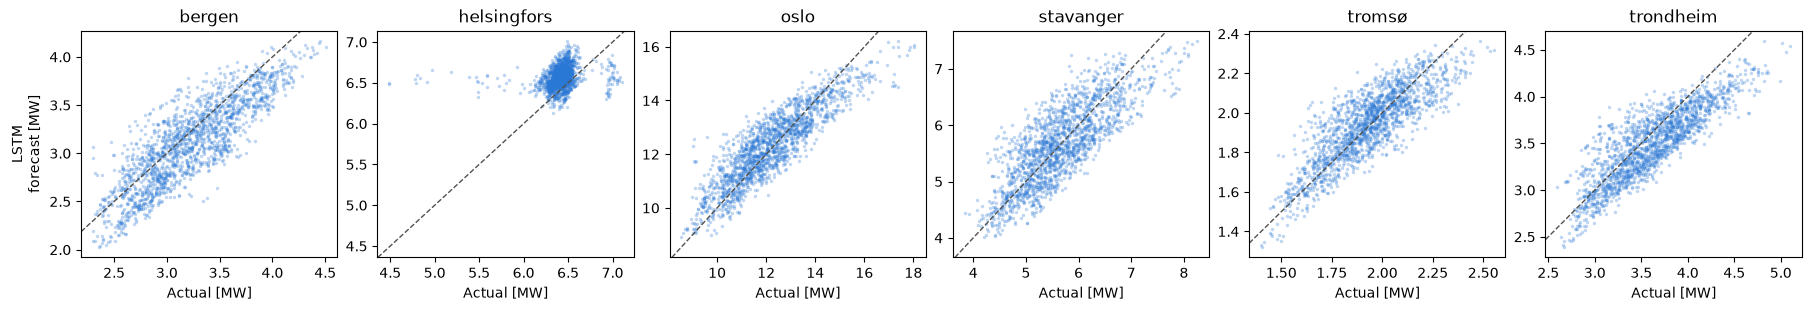

In [14]:
validator.plot_predicted_vs_actual_consumption(no_baseline=True)

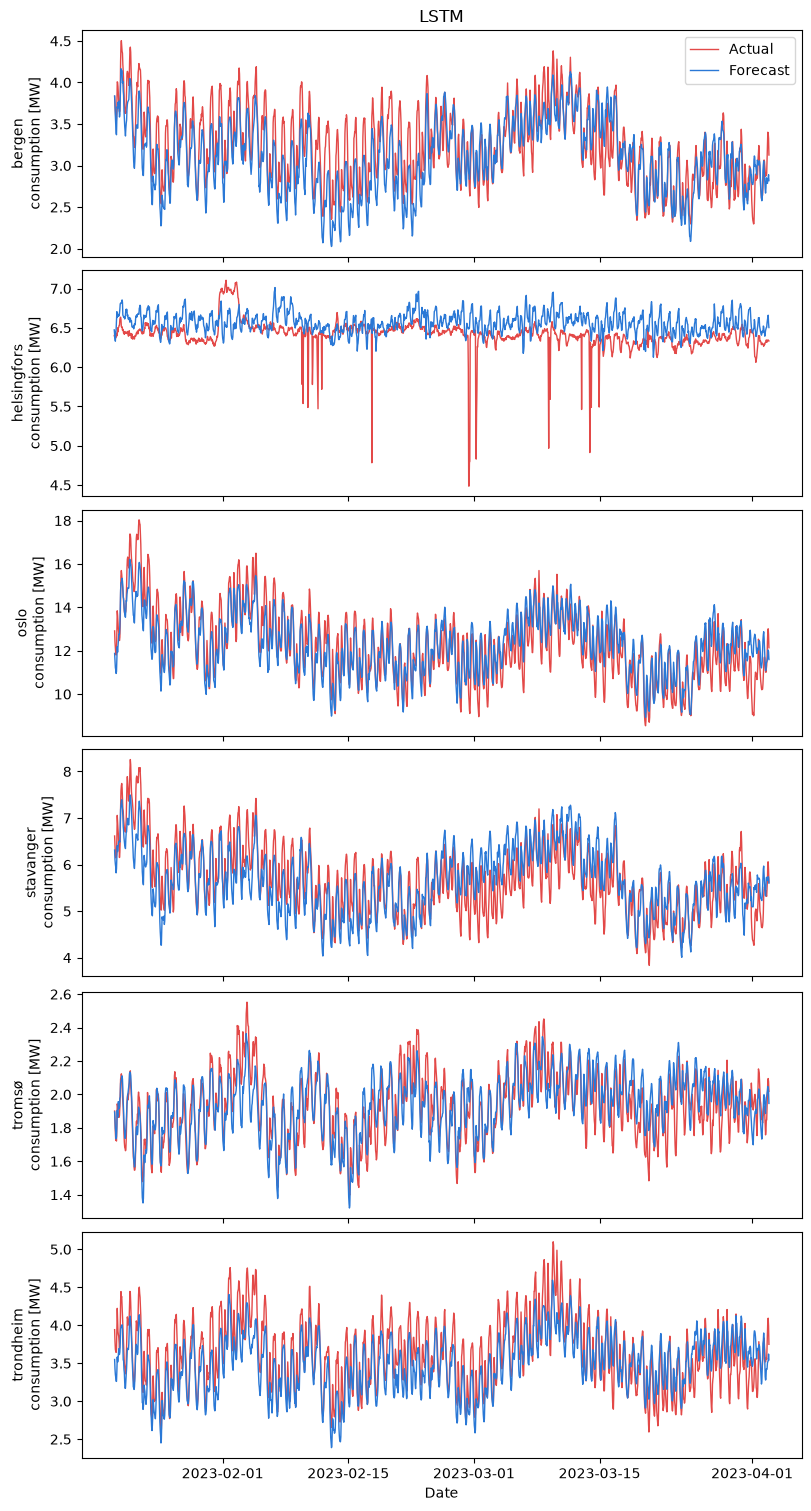

In [15]:
validator.plot_consumption_over_time(test["time"], no_baseline=True)